Clean Tweets:
ai changing technology software development
machine learning ai growing rapidly
python popular machine learning
technology companies investing ai
students learning python data science
data science machine learning useful skills


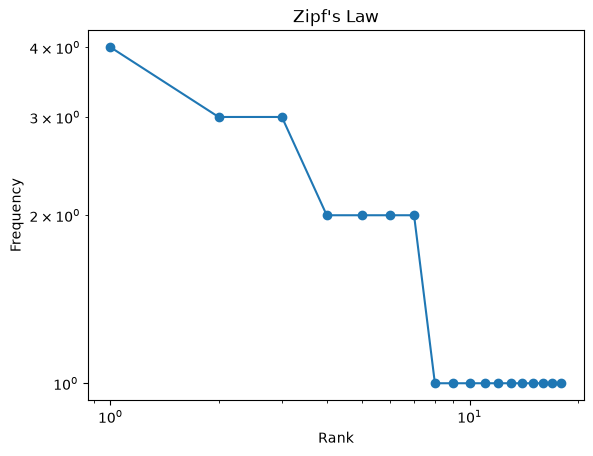

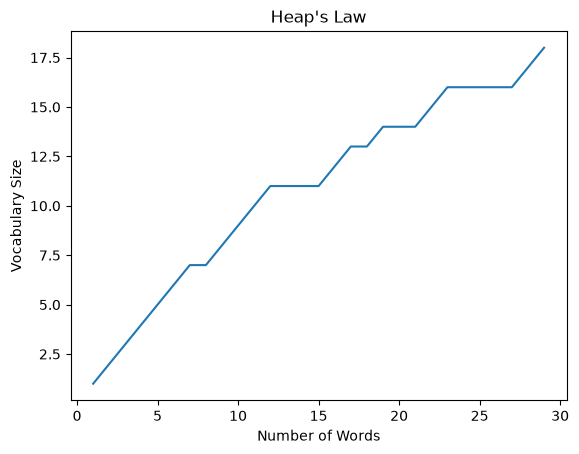

Topic 1 : ['ai', 'data', 'science', 'machine', 'learning']
Topic 2 : ['popular', 'investing', 'companies', 'ai', 'technology']


In [2]:
import re
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

tweets = [
    "AI is changing technology and software development",
    "Machine learning and AI are growing rapidly",
    "Python is popular for machine learning",
    "Technology companies are investing in AI",
    "Students are learning Python and data science",
    "Data science and machine learning are useful skills"
]

# Preprocessing
stop = {"is", "the", "and", "are", "for", "in", "to", "a", "of"}

clean = []
for t in tweets:
    t = re.sub(r"http\S+|@\w+|#\w+", "", t.lower())
    t = re.sub(r"[^a-z\s]", "", t)
    clean.append(" ".join(w for w in t.split() if w not in stop))

print("Clean Tweets:")
print(*clean, sep="\n")

# Zipf's Law
words = " ".join(clean).split()
freq = sorted(Counter(words).values(), reverse=True)

plt.loglog(range(1, len(freq)+1), freq, marker="o")
plt.title("Zipf's Law")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.show()

# Heap's Law
vocab = []
seen = set()

for word in words:
    seen.add(word)
    vocab.append(len(seen))

plt.plot(range(1, len(words)+1), vocab)
plt.title("Heap's Law")
plt.xlabel("Number of Words")
plt.ylabel("Vocabulary Size")
plt.show()

# Topic Identification
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(clean)

lda = LatentDirichletAllocation(n_components=2, random_state=42)
lda.fit(X)

terms = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    print("Topic", i+1, ":", 
          [terms[j] for j in topic.argsort()[-5:]])